# Tutorial 3 — The triangulation map

**A window that resolves the companion delivers one number, its along-scan
position η with an error bar σ; that fixes the companion on a line of the
sky. The triangulation map pools those lines: each detection deposits a
Gaussian ridge along its line, the ridges are summed, and the companion is
where they cross.** This page builds the map step by step on a well-sampled
campaign of a static scene, explains the one choice that matters (the
ridges have unit area), reads the map with `bp.map_peak`, and then shows where
it is ambiguous. The functions are `bp.backprojection_map`, `bp.map_peak` and
`bp.peak_consistency` in `scanlib.backprojection`.

**What you will see.**

1. A detection is a line; with its error bar it is a ridge, Gaussian in the
   perpendicular distance from the line.
2. Why each ridge has unit area, not unit height: a broad detection must
   not deposit more than a tight one.
3. The map built up over 3, 10 and all 76 detections: the crossing sharpens,
   the stray mass does not.
4. Reading the map: its peak outside the primary's zone, the map's own width
   there, and which detections pass through it. The peak is a seed for the
   joint fit, never a measurement.
5. Where the map is ambiguous: scan directions in a few bundles stretch the
   peak; a crowded field makes ghost crossings; and a wrong detection
   moves the peak of a sum of many lines little where it pulls the peak
   of a product, while among few lines it can carry the sum's peak too.

The package makes detections from the windows with the per-window
reduction (`reduce_campaign`; quickstart 1, block 5). This page uses the
stand-in of tutorial 0, the truth plus the error the window's own Fisher
matrix predicts, so that the map is seen alone. The scene is static: the map has no
motion in it.

Conventions as in the other tutorials: ψ in rad counter-clockwise from
north, offsets in mas from the primary, η = Δα\* sin ψ + Δδ cos ψ; maps with
rows = Δδ, columns = Δα\*, east to the left, in gray with zero at white, the
primary a plus and each true source an open star.

| block | task | calls | paper |
|---|---|---|---|
| setup | the instrument, the static pair, the detections (a stand-in for the per-window reduction) | `ins.Instrument.gaussian`, `joint.scene_positions_al`, `inst.design_columns`, `inst.design_jacobian` | Sect. 2.2, Eq. 8; App. B.1 |
| 1 | a detection as a line and as a ridge; the map of three | `bp.backprojection_map` | Sect. 3.1, Eq. 10; Sect. 3.3, Eq. 13 |
| 2 | unit area against unit height | `bp.backprojection_map` | Sect. 3.3, Eq. 13; App. C.1 |
| 3 | the map built up over 3, 10 and all detections | `bp.backprojection_map` | Sect. 3.3, Eq. 13 |
| 4 | the peak, the map's width there, the lines through it | `bp.map_peak`, `bp.peak_consistency` | Sect. 3.3 |
| 5 | where the map is ambiguous | `bp.backprojection_map`, `bp.map_peak` | Sects. 3.3 and 5.1; App. C.1; Fig. C.1 |

Every scanlib call carries the name of its module (`joint.fit_joint`); the first code cell lists the modules.

**The series.** [One scene, forty windows](00_three_images_and_fit.ipynb), then one page per image: [the inverse Radon transform](01_inverse_radon.ipynb), [faststack](02_faststack.ipynb), this page; then where each step's premise breaks, in [`limitations/`](limitations/) (for the map: [few lines](limitations/03_few_lines.ipynb)). The pipeline itself, from the windows to the measurement, is in [`../quickstart/`](../quickstart/).

**Symbols and units** are defined once for the package and every notebook in [`docs/conventions.md`](../../docs/conventions.md). This page uses ψ, (Δα\*, Δδ), η, σ_η and the detections, the map and its width, and the laws.

In [1]:
# the imports: numpy, matplotlib, and the scanlib modules; every scanlib call below carries its module's name
import numpy as np
import matplotlib.pyplot as plt

from scanlib import instrument as ins      # the instrument: sampling, LSF, the along-scan projection (Eq. 9)
from scanlib import backprojection as bp   # the triangulation map and its peak
from scanlib import joint                  # the joint fit of all windows, and its helpers

In [2]:
# The instrument, defined once: 18 samples 59 mas apart, a Gaussian LSF of
# FWHM 100 mas, and the trial positions of the per-window reduction.
inst = ins.Instrument.gaussian(fwhm_mas=100.0, pitch_mas=59.0, n_samples=18)
grid = inst.sample_grid_mas
sigma_noise = 10.0                           # the primary's total flux is 100 sigma

In [3]:
# the static pair: the companion at 200 mas, position angle 110 deg, one fifth as bright; 80 even directions
# over the half-turn; the sky grid (half-size 400 mas, 2 mas pixels); the one random generator of this page
position_angle = np.deg2rad(110.0)           # of the companion, from north through east [rad]
theta = np.array([200.0 * np.sin(position_angle), 200.0 * np.cos(position_angle)])   # the companion (dra*, ddec) [mas]
flux = np.array([1000.0, 200.0])             # the fluxes per sample, primary first
EVEN = np.linspace(0.0, np.pi, 80, endpoint=False) + 0.01    # 80 even directions [rad]; 0.01 keeps them off the axes
half = 400.0                                 # the half-size of the sky grid [mas]
step = 2.0                                   # its pixel [mas]
# the seed is one number, 8: a label only (why 8: not stated). The generator's draws are the detections' errors,
# in the order of the calls of detections(): the even directions, then the Gaia forecast, then the crowded field
rng_detections = np.random.default_rng(8)

In [4]:
# the stand-in's error: the Fisher sigma of each companion's along-scan position in one window
def sigma_eta(eta, flux):
    """The error that one window's Fisher matrix predicts for each companion's along-scan position, with all the
    fluxes free. The stand-in of this page draws each detection's error from it.

    Inputs
        eta    the along-scan positions of the sources in the window [mas], primary first
        flux   their fluxes per sample, primary first
    Returns
        the Fisher 1-sigma of each companion's position [mas], one number per companion (the primary has none);
        all infinite where the Fisher matrix is singular
    The instrument `inst` and the noise sigma `sigma_noise` are the page's."""
    n_companions = eta.size - 1

    # step 1, the model's pieces. unit_profiles: one column per source, the samples a unit flux at its position
    # produces. profile_slopes: the derivative of each column with respect to its source's position [1/mas]
    unit_profiles = inst.design_columns(eta)
    profile_slopes = inst.design_jacobian(eta)

    # step 2, the Jacobian of the window's model: one column per companion's position (its slope times its
    # flux), then one column per flux. profile_slopes[:, 1:] and flux[1:] omit the primary (column 0): its
    # position is fixed at the origin
    jacobian = np.column_stack([profile_slopes[:, 1:] * flux[1:], unit_profiles])

    # step 3, the Fisher matrix; a condition number above 1e12 counts as singular
    fisher = jacobian.T @ jacobian / sigma_noise ** 2
    if np.linalg.cond(fisher) > 1e12:
        return np.full(n_companions, np.inf)

    # step 4, the inverse of the Fisher matrix is the covariance, and its diagonal holds the variances: the
    # first n_companions entries are the companions' positions; the entries after them, omitted, are the fluxes
    variances = np.diag(np.linalg.inv(fisher))
    return np.sqrt(variances[:n_companions])

In [5]:
# the stand-in for the per-window reduction: a detection is the truth plus one draw of the Fisher sigma
def detections(theta, psi, flux=flux, sigma_max=30.0, rng=rng_detections):
    """The detections of a static scene, by the stand-in: one detection per window and companion whose Fisher
    sigma is finite and not above sigma_max. A detection's position is the truth plus one Gaussian draw of that
    sigma.

    Inputs
        theta       the companions' positions, a flat vector (dra*, ddec) [mas] per companion
        psi         the scan angles [rad], one per window
        flux        the fluxes per sample, primary first (default: the pair's)
        sigma_max   the largest error that still gives a detection [mas]
        rng         the random generator of the draws (default: the page's)
    Returns three arrays, one entry per detection
        the scan angle [rad], the along-scan position [mas], its error [mas]"""
    # step 1, truth: row j of eta_true holds the along-scan positions [mas] of the sources in window j
    eta_true = joint.scene_positions_al(theta, psi)

    # step 2, the windows in the order of the angles, and in each window the companions in their order; a draw
    # is made only for a detection that is kept
    det_psi = []
    det_eta = []
    det_sigma = []
    for psi_j, eta_j in zip(psi, eta_true):
        sigma_j = sigma_eta(eta_j, flux)                     # one error per companion
        for index in range(sigma_j.size):
            sigma = sigma_j[index]
            column = index + 1                               # column 0 of eta_j is the primary: no detection
            if np.isfinite(sigma) and sigma <= sigma_max:
                det_psi.append(psi_j)
                det_eta.append(eta_j[column] + rng.normal(0.0, sigma))
                det_sigma.append(sigma)
    return np.array(det_psi), np.array(det_eta), np.array(det_sigma)

In [6]:
# truth: the detections of the pair on the 80 even directions
det_psi, det_eta, det_sigma = detections(theta, EVEN)
print(f"{det_psi.size} detections from {EVEN.size} windows; "
      f"sigma from {det_sigma.min():.1f} to {det_sigma.max():.1f} mas")

76 detections from 80 windows; sigma from 4.6 to 24.2 mas


In [7]:
# the paper's figure style: font 10, ticks 9 and inward, thin axes; grays first, one accent
plt.rcParams.update({"font.size": 10.0, "axes.linewidth": 0.5, "xtick.labelsize": 9.0, "ytick.labelsize": 9.0,
                     "xtick.direction": "in", "ytick.direction": "in", "legend.frameon": False, "legend.fontsize": 7.5})
ACCENT = "tomato"                                          # the one accent
# TRUTH, SEED, PRIMARY: three tables of options for ax.scatter (the marker, its size, its colours, its line
# width, its drawing order), one per kind of point
TRUTH = dict(marker="*", s=150, facecolor="white", edgecolor="k", lw=0.8, zorder=7)   # the truth
SEED = dict(marker="o", s=60, facecolor="none", edgecolor=ACCENT, lw=1.1, zorder=6)  # a starting point (the map's peak)
PRIMARY = dict(marker="+", s=110, color="k", lw=1.4, zorder=6)                       # the primary
EAST = r"$\Delta\alpha^{*}$  [mas]   (East $\leftarrow$)"
NORTH = r"$\Delta\delta$  [mas]"


def letter(ax, panel_letter, text=""):
    """Write the panel letter, bold, inside the top-left corner of a panel, and a few words after it.

    Inputs
        ax             the panel (a matplotlib Axes)
        panel_letter   the letter, for example "a"; None: the words alone
        text           the words after the letter
    Returns nothing."""
    if panel_letter is None:
        head = ""
    else:
        head = rf"$\bf{{({panel_letter})}}$ "
    ax.text(0.04, 0.96, head + text, transform=ax.transAxes, va="top", ha="left", fontsize=9,
            bbox=dict(fc="white", ec="none", pad=1.0, alpha=0.8))

In [8]:
# the helper that draws one map: gray with zero at white, east to the left, the primary and the truth marked
def show(ax, sky, axis, panel_letter, text, marks=None, **imshow_options):
    """Draw one map on a panel, east to the left, in gray with zero at white, and mark the sources. The primary
    is a plus, each true source an open star, so that the map shows inside it.

    Inputs
        ax               the panel (a matplotlib Axes)
        sky              the map, rows ddec and columns dra*
        axis             the coordinates of the map's pixels along either side [mas]
        panel_letter     the panel's letter; None: no letter
        text             the words after the letter
        marks            the (dra*, ddec) [mas] of the sources to mark, one row each, primary first; None: the
                         primary and the companion
        imshow_options   any other option, handed to ax.imshow
    Returns
        the drawn map (a matplotlib AxesImage)"""
    # step 1, the map; the gray scale and its zero, unless the caller gave its own
    imshow_options.setdefault("cmap", "gray_r")
    imshow_options.setdefault("vmin", 0.0)
    extent = (axis[0], axis[-1], axis[0], axis[-1])              # the first and the last coordinate, for both sides
    drawn = ax.imshow(sky, origin="lower", extent=extent, interpolation="nearest", rasterized=True,
                      **imshow_options)

    # step 2, the sources to mark: row 0 is the primary, the other rows the true sources
    if marks is None:
        marks = np.vstack([[0.0, 0.0], theta])
    ax.scatter(marks[0, 0], marks[0, 1], **PRIMARY)

    # step 3, the truth, drawn twice: an open star with a white rim, then the same star with its black edge over
    # it, to show on a dark peak too. {**TABLE, "key": value}: a copy of the table with that entry replaced
    star_rim = {**TRUTH, "facecolor": "none", "s": 260, "edgecolor": "w", "lw": 2.4}
    star_edge = {**TRUTH, "facecolor": "none", "s": 260}
    ax.scatter(marks[1:, 0], marks[1:, 1], **star_rim)
    ax.scatter(marks[1:, 0], marks[1:, 1], **star_edge)

    # step 4, the letter and the axes
    letter(ax, panel_letter, text)
    ax.set_aspect("equal")
    ax.set_xlim(axis[-1], axis[0])                                               # east to the left
    ax.set_xlabel(EAST)
    return drawn

## 1. A detection is a line, with its error bar a ridge

*Paper: Sect. 3.1, Eq. 10 (the line); Sect. 3.3, Eq. 13 (the map).*

A window at scan angle ψ that measures the companion at η = η̂ ± σ says only
that the companion lies on the line

$$\Delta\alpha^* \sin\psi + \Delta\delta \cos\psi = \hat\eta$$

somewhere; the window saw nothing across the scan. The line's normal is the
unit vector (sin ψ, cos ψ), so the perpendicular distance of a sky point
from the line is d = Δα\* sin ψ + Δδ cos ψ − η̂, in mas, and the error bar
turns the line into a ridge, Gaussian in d with width σ:

$$R_i(\Delta\alpha^*, \Delta\delta) = \frac{1}{\sqrt{2\pi}\,\sigma_i}
\exp\!\left(-\frac{d_i^2}{2\sigma_i^2}\right), \qquad
\text{map} = \sum_i R_i .$$

The figure draws three detections as lines with their ±σ bands, and the map
of those three: three ridges, crossing at the companion.

In [9]:
# three detections, chosen by their index for three well-separated scan angles, and their map on the page's
# sky grid (half-size 400 mas, 2 mas pixels). bp.backprojection_map returns the map, its axis and a third
# output that `_` drops
pick = [2, 14, 27]                           # the indices of the three detections
axis = np.arange(-half, half + 1e-9, step)   # the pixels' coordinates along either side [mas]
# det_psi[pick] keeps the three picked entries; the same for det_eta and det_sigma
sky3, axis, _ = bp.backprojection_map(det_psi[pick], det_eta[pick], det_sigma[pick], half, step)

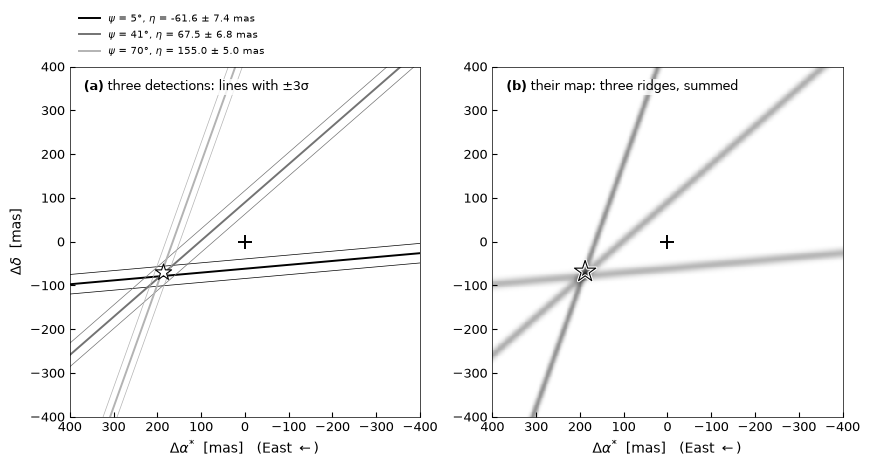

In [10]:
# Figure 1: the three detections as lines with their edges at -3 and +3 sigma, the primary (plus) and the
# companion's true position (star); beside it the map of the three
fig, axes = plt.subplots(1, 2, figsize=(8.8, 4.7))
ax = axes[0]
for i, gray in zip(pick, ("k", "0.45", "0.7")):              # i: the index of a picked detection
    psi_i = det_psi[i]
    eta_i = det_eta[i]
    sigma_i = det_sigma[i]
    # the line: points (dra*, ddec) with dra* sin psi + ddec cos psi = eta
    normal = np.array([np.sin(psi_i), np.cos(psi_i)])        # unit vector across the line (the scan direction)
    along = np.array([np.cos(psi_i), -np.sin(psi_i)])        # unit vector along the line
    foot = eta_i * normal                                    # the point of the line nearest the origin
    # the line, thick, and its two edges at -3 and +3 sigma: k is the shift across the line, in sigmas
    for k, line_width in ((0, 1.4), (-3, 0.5), (3, 0.5)):
        # the two ends of the line, 600 mas to either side of its foot; np.outer makes one row per end
        line_ends = foot + k * sigma_i * normal + np.outer([-600, 600], along)
        ax.plot(line_ends[:, 0], line_ends[:, 1], color=gray, lw=line_width)
    # an empty line: it draws nothing and gives the legend its entry
    ax.plot([], [], color=gray, lw=1.4,
            label=rf"$\psi$ = {np.degrees(psi_i):.0f}°, $\eta$ = {eta_i:.1f} ± {sigma_i:.1f} mas")
ax.scatter(0, 0, **PRIMARY)
ax.scatter(theta[0], theta[1], **TRUTH)
letter(ax, "a", "three detections: lines with ±3σ")
ax.set(xlim=(half, -half), ylim=(-half, half), aspect="equal", xlabel=EAST, ylabel=NORTH)
ax.legend(loc="lower left", bbox_to_anchor=(0.0, 1.0))
show(axes[1], sky3, axis, "b", "their map: three ridges, summed")
plt.tight_layout()
plt.show()

## 2. Unit area, not unit height

*Paper: Sect. 3.3, Eq. 13; App. C.1 (the map as a positional statistic).*

The detections are not equally precise: a scan along the pair resolves the
companion to a few mas, one nearly across it to tens of mas. How should a
broad ridge compare with a tight one? Each ridge is normalized to **unit
area** across its line, 1/(√(2π) σ) at its crest. The alternative, every
ridge of unit height, would integrate to √(2π) σ: a detection ten times
less precise would deposit ten times the mass, and the least informative
windows would dominate the map. Unit area gives every detection the same
total mass and lets precision show as concentration: a tight detection is
a tall narrow ridge that localises hard, a broad one a low plateau that
washes out. This is not inverse-variance weighting: a ridge's crest scales
as 1/σ and its curvature there as 1/σ³, while weighted least squares, the
product of the same Gaussians, weighs each line by 1/σ². The map is a
proposal, not a likelihood; the joint fit of the windows weighs the data.
The figure compares the two choices on the same detections, with the
cross-sections of a tight and a broad ridge.

In [11]:
# the map of all detections (unit-area ridges, Eq. 13), and the same sum with every ridge of unit height
sky, axis, _ = bp.backprojection_map(det_psi, det_eta, det_sigma, half, step)
# sky_dra, sky_ddec: the dra* and the ddec of every pixel [mas]; rows are ddec, columns dra*
sky_dra, sky_ddec = np.meshgrid(axis, axis)
unit_height = np.zeros_like(sky_dra)
for psi_i, eta_i, sigma_i in zip(det_psi, det_eta, det_sigma):
    # every pixel's perpendicular distance from the detection's line [mas]
    distance_from_line = sky_dra * np.sin(psi_i) + sky_ddec * np.cos(psi_i) - eta_i
    unit_height += np.exp(-0.5 * (distance_from_line / sigma_i) ** 2)
# the indices of the most and the least precise detection, and the distances for their cross-sections
tight = np.argmin(det_sigma)
broad = np.argmax(det_sigma)
cross_distance = np.linspace(-60, 60, 400)   # perpendicular distances for Figure 2 (a) [mas]

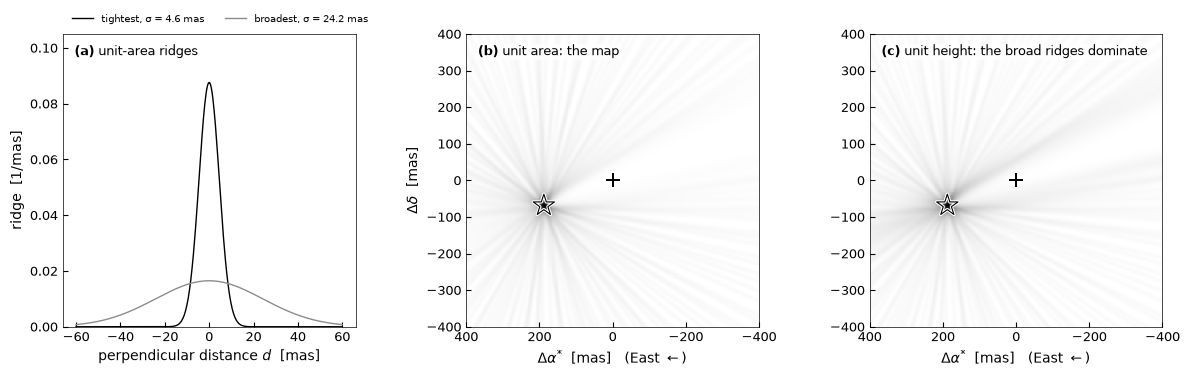

In [12]:
# Figure 2: the cross-sections of the tightest and the broadest ridge, and the two maps
fig, axes = plt.subplots(1, 3, figsize=(12.0, 4.3))
# one row per curve: the detection's sigma [mas], its name, its gray
curves = ((det_sigma[tight], "tightest", "k"),
          (det_sigma[broad], "broadest", "0.55"))
for sigma, name, gray in curves:
    # the unit-area ridge of the text: a Gaussian in the distance, with the crest 1 / (sqrt(2 pi) sigma)
    ridge = np.exp(-0.5 * (cross_distance / sigma) ** 2) / (np.sqrt(2 * np.pi) * sigma)
    axes[0].plot(cross_distance, ridge, color=gray, lw=1, label=f"{name}, σ = {sigma:.1f} mas")
axes[0].set(xlabel="perpendicular distance $d$  [mas]", ylabel="ridge  [1/mas]", ylim=(0.0, 0.105))
letter(axes[0], "a", "unit-area ridges")
axes[0].set_box_aspect(1)                                  # square, as the two maps beside it
axes[0].legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=2)
show(axes[1], sky, axis, "b", "unit area: the map")
show(axes[2], unit_height, axis, "c", "unit height: the broad ridges dominate")
axes[1].set_ylabel(NORTH)
plt.tight_layout()
plt.show()

## 3. The map built up

*Paper: Sect. 3.3, Eq. 13.*

With more detections the crossing at the companion grows in proportion to
their number, because every ridge passes through it, while elsewhere each
ridge stands alone. The map's value at the companion is the sum of the
crests, and the stray mass is spread over the whole sky. The figure builds
the map from 3, 10 and all 76 detections (80 windows; four deliver none).

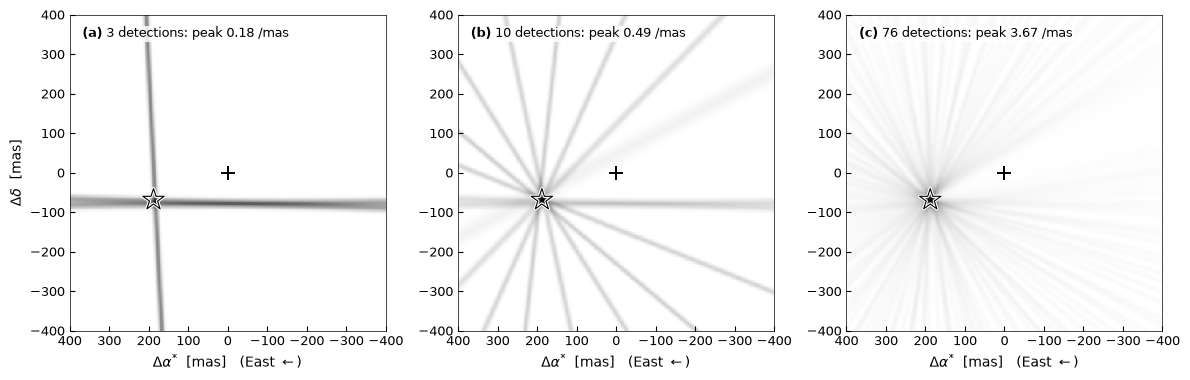

In [13]:
# Figure 3: the map over 3, 10 and all detections, on one gray scale per panel. `selected` holds n_shown indices
# spread evenly over the detections, so each subset covers the half-turn
fig, axes = plt.subplots(1, 3, figsize=(12.0, 4.1))
for ax, panel_letter, n_shown in zip(axes, "abc", (3, 10, det_psi.size)):
    selected = np.linspace(0, det_psi.size - 1, n_shown).astype(int)
    # the map of the subset; the two `_` drop the map's axis (it equals `axis`) and its third output
    sky_n, _, _ = bp.backprojection_map(det_psi[selected], det_eta[selected], det_sigma[selected], half, step)
    show(ax, sky_n, axis, panel_letter, f"{n_shown} detections: peak {sky_n.max():.2f} /mas")
axes[0].set_ylabel(NORTH)
plt.tight_layout()
plt.show()

## 4. Reading the map

*Paper: Sect. 3.3 (the strongest peak away from the primary, and the detections through it).*

`bp.map_peak` finds the highest local maximum of the map farther than an
origin zone (30 mas by default) from the primary, which delivers no
detection and must not be mistaken for a companion, and returns with it
the map's own width there: the rms half-width, across its narrow
direction, of the region above half the peak. That width is the map's
resolution at the peak. `bp.peak_consistency` then says which detections'
lines pass within k σ (floored by that width) of the peak.

The peak is a **seed**. The map is a sum of ridges, not a likelihood: its
peak is where the lines cross on a pixel grid, and its width is set by the
detections' errors and the grid, not by the data's full information. The
measurement, position and flux with their covariance, is the joint fit of
all windows (`scanlib.joint`, tutorial 0), seeded from this peak.

In [14]:
# the map's peak on 1 mas pixels, its width, and the detections consistent with it: `keep` is a mask over the
# detections (True where the line passes the peak), `distance` each line's distance from the peak [mas].
# truth: the peak against the true position
PEAK_STEP_MAS = 1.0                          # the pixel of the finer map on which the peak is read [mas]
# bp.map_peak returns the peak (dra*, ddec) [mas], the map's width there [mas], the finer map and its axis
peak, width, sky1, axis1 = bp.map_peak(det_psi, det_eta, det_sigma, half, PEAK_STEP_MAS)
keep, distance = bp.peak_consistency(det_psi, det_eta, det_sigma, peak, width)
peak_error = np.array(peak) - theta          # the peak minus the true position, (dra*, ddec) [mas]
print(f"peak at ({peak[0]:.1f}, {peak[1]:.1f}) mas, width {width:.1f} mas; "
      f"truth ({theta[0]:.1f}, {theta[1]:.1f}) mas, offset {np.hypot(peak_error[0], peak_error[1]):.1f} mas")
print(f"{keep.sum()} of {keep.size} detections pass within max(3 sigma, width) of the peak; "
      f"largest distance {distance.max():.1f} mas")

peak at (187.0, -69.0) mas, width 6.8 mas; truth (187.9, -68.4) mas, offset 1.1 mas
76 of 76 detections pass within max(3 sigma, width) of the peak; largest distance 23.3 mas


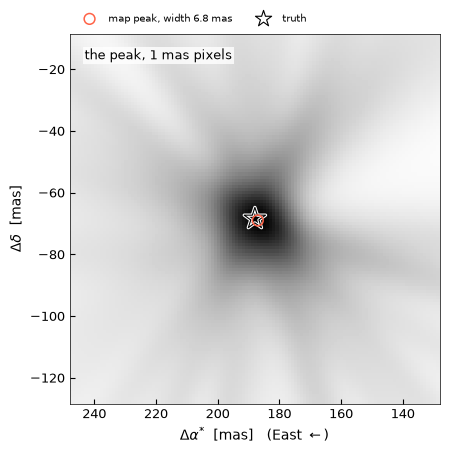

In [15]:
# Figure 4: the map around the companion; the peak is a seed (open circle), the truth an open star
fig, ax = plt.subplots(figsize=(4.6, 4.7))
show(ax, sky1, axis1, None, "the peak, 1 mas pixels")
ax.set(ylim=(theta[1] - 60, theta[1] + 60), xlim=(theta[0] + 60, theta[0] - 60), ylabel=NORTH)
# {**TABLE, "key": value}: a copy of the table of options with that one entry replaced
seed_style = {**SEED, "zorder": 9}                                               # drawn over the star
ax.scatter(peak[0], peak[1], **seed_style, label=f"map peak, width {width:.1f} mas")
# an empty scatter: it draws nothing and gives the legend its entry for the star that show() drew
legend_star = {**TRUTH, "facecolor": "none"}
ax.scatter([], [], **legend_star, label="truth")
ax.legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=2)
plt.tight_layout()
plt.show()

## 5. Where the map is ambiguous

*Paper: Sect. 3.3 (other sources and spurious detections add lines); Sect. 5.1 (the search among several sources); App. C.1 (the sum against the product); Fig. C.1 (the map on two scan laws).*

**Scan directions in a few bundles.** The crossing is sharp only across the
directions that were scanned. With the Gaia forecast's 40 angles (tutorial
1, section 4), which come in two bundles about 90° apart, the ridges cross
at a shallow set of angles and the peak stretches along the directions no
window measured. Across the scanned bundle it is as sharp as on the even
set or sharper, which is the width `bp.map_peak` reports; along the other
axis it is several times longer, and the seed is correspondingly poorer
there.

**A crowded field.** Every ridge of every source crosses every ridge of
every other somewhere. With three sources on 80 directions the map shows
the three real crossings, and between them a web of pairwise crossings of
unrelated ridges, the *ghosts*. Ghosts are lower (two ridges, not 80) but a
faint source can be lower still. The map alone cannot tell them apart; the
search that can is the map ladder (`map_ladder` in `scanlib.search`; the
quickstart 3), which tests each proposed crossing on the windows with
a likelihood ratio.

**A wrong detection.** One stray ridge adds one crest's worth of mass along
its line. A product of the same Gaussians, the likelihood of the
detections, is a weighted least squares: a confidently wrong detection
pulls its peak away from the crossing in proportion to its weight, and
nothing in the product says which line was wrong. The figure adds one
detection 100 mas off its line with a claimed error of 2 mas and compares
the sum with the product (shown as the exponential of the summed
log-ridges), both within 100 mas of the companion. Among these 76 lines
the sum's peak moves by about 1 mas and the product's by about 18. A sum is
less sensitive than a product, not immune: the stray crest, 1/(√(2π) σ) =
0.20 per mas at σ = 2 mas, is taller than a crossing of n ridges of
σ = 10 mas, n × 0.040 per mas, whenever n < 5, and `bp.map_peak` then returns
a point on the wrong line. Few lines, or one line much more precise than
the rest, are where the map needs `bp.peak_consistency` and the joint fit.

In [16]:
# the Gaia forecast's 40 scan angles, from the reference cases; the detections and the map on them
ref = np.load("../../tests/reference/reference_cases.npz")
GAIA = ref["static_pair/inputs/psi"]
gaia_psi, gaia_eta, gaia_sigma = detections(theta, GAIA)
# the two `_` drop the map's axis (it equals `axis`) and its third output
sky_gaia, _, _ = bp.backprojection_map(gaia_psi, gaia_eta, gaia_sigma, half, step)

In [17]:
# the peak's two half-widths: bp.map_peak returns the narrow one; the long one is computed here the same way
def peak_axes(psi, eta, sigma):
    """The map's peak and the size of the peak across its narrow and along its long direction (bp.map_peak
    returns the narrow one only).

    Inputs
        psi, eta, sigma   the detections: scan angle [rad], along-scan position [mas], error [mas], one entry
                          per detection
    Returns three things
        peak     the (dra*, ddec) of the map's peak [mas]
        narrow   the rms half-width of the region above half the peak, across its narrow direction [mas]
        long_    the same along its long direction [mas]"""
    # step 1, the peak, and the map on 1 mas pixels with its axis (the map's own width, the name _, is dropped)
    peak, _, fine_sky, fine_axis = bp.map_peak(psi, eta, sigma, half, 1.0)
    fine_dra, fine_ddec = np.meshgrid(fine_axis, fine_axis)      # the dra* and the ddec of every pixel [mas]

    # step 2, the mask `region` keeps the pixels above half the peak; fine_dra[region], fine_ddec[region] are
    # their coordinates. moments: the 2 x 2 covariance of those pixels' offsets from the peak [mas^2]
    region = fine_sky >= 0.5 * fine_sky.max()
    offsets = np.vstack([fine_dra[region] - peak[0], fine_ddec[region] - peak[1]])
    moments = np.cov(offsets)

    # step 3, the eigenvalues come in ascending order: the narrow direction first, then the long one
    narrow, long_ = np.sqrt(np.linalg.eigvalsh(moments))
    return peak, narrow, long_

In [18]:
# the two half-widths on the even directions and on the Gaia forecast's
# one row per set of detections: its name, then its scan angles, positions and errors
sets = (("80 even directions", det_psi, det_eta, det_sigma),
        ("Gaia forecast", gaia_psi, gaia_eta, gaia_sigma))
for name, set_psi, set_eta, set_sigma in sets:
    set_peak, narrow, long_ = peak_axes(set_psi, set_eta, set_sigma)
    print(f"{name:20s}: peak ({set_peak[0]:.0f}, {set_peak[1]:.0f}) mas, "
          f"half-widths {narrow:.1f} across, {long_:.1f} along")

80 even directions  : peak (187, -69) mas, half-widths 6.8 across, 8.8 along
Gaia forecast       : peak (189, -67) mas, half-widths 4.2 across, 22.2 along


In [19]:
# a crowded field: three companions, as (dra*, ddec) pairs in one flat vector, and four fluxes, primary first
theta3 = np.array([theta[0], theta[1], -200.0, 230.0, 120.0, 250.0])
flux3 = np.array([1000.0, 200.0, 400.0, 150.0])
crowded_psi, crowded_eta, crowded_sigma = detections(theta3, EVEN, flux3)
# the two `_` drop the map's axis (it equals `axis`) and its third output
sky_crowded, _, _ = bp.backprojection_map(crowded_psi, crowded_eta, crowded_sigma, half, step)

In [20]:
# a wrong detection: the sum (the map) and the logarithm of the product, on the page's sky grid
bad_eta = det_eta.copy()                                        # copies: the clean detections stay as they are
bad_sigma = det_sigma.copy()
WRONG = 5                                                       # the index of the detection made wrong
bad_eta[WRONG] += 100.0                                         # one detection 100 mas off its line,
bad_sigma[WRONG] = 2.0                                          # claiming 2 mas
sky_bad, _, _ = bp.backprojection_map(det_psi, bad_eta, bad_sigma, half, step)
# the logarithm of the product of the Gaussians: the sum over the detections of -0.5 (distance / sigma)^2
log_product = np.zeros_like(sky_dra)
for psi_i, eta_i, sigma_i in zip(det_psi, bad_eta, bad_sigma):
    distance_from_line = sky_dra * np.sin(psi_i) + sky_ddec * np.cos(psi_i) - eta_i
    log_product += -0.5 * (distance_from_line / sigma_i) ** 2

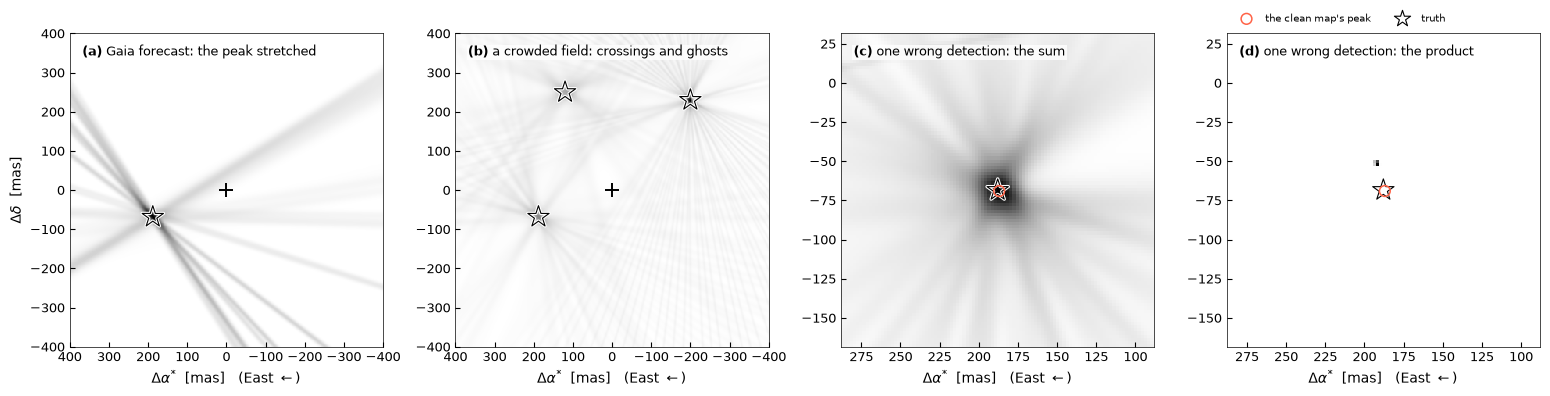

In [21]:
# Figure 5: the four maps. theta3.reshape(-1, 2) makes the flat vector three (dra*, ddec) rows; axes[2:] are
# the last two panels, drawn within 100 mas of the companion
fig, axes = plt.subplots(1, 4, figsize=(15.6, 4.3))
show(axes[0], sky_gaia, axis, "a", "Gaia forecast: the peak stretched")
crowded_marks = np.vstack([[0.0, 0.0], theta3.reshape(-1, 2)])          # the primary's row, then the three companions
show(axes[1], sky_crowded, axis, "b", "a crowded field: crossings and ghosts", marks=crowded_marks)
show(axes[2], sky_bad, axis, "c", "one wrong detection: the sum")
# the product, scaled to 1 at its highest pixel: the exponential of the log-product minus its maximum
product = np.exp(log_product - log_product.max())
show(axes[3], product, axis, "d", "one wrong detection: the product")
seed_style = {**SEED, "zorder": 9}                                             # drawn over the star
for ax in axes[2:]:
    ax.scatter(peak[0], peak[1], **seed_style, label="the clean map's peak")
    ax.set(xlim=(theta[0] + 100, theta[0] - 100), ylim=(theta[1] - 100, theta[1] + 100))
# an empty scatter: it draws nothing and gives the legend its entry for the star that show() drew
legend_star = {**TRUTH, "facecolor": "none"}
axes[3].scatter([], [], **legend_star, label="truth")
axes[3].legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=2)
axes[0].set_ylabel(NORTH)
plt.tight_layout()
plt.show()

In [22]:
# truth: where the sum and the product peak with the wrong detection
def argmax_sky(sky):
    """The position of the highest pixel of a map on the page's axis.

    Inputs
        sky   the map, rows ddec and columns dra*
    Returns
        the (dra*, ddec) of its highest pixel [mas]"""
    # np.argmax numbers the pixels in one row; np.unravel_index turns that number into i, the row (ddec), and
    # j, the column (dra*)
    i, j = np.unravel_index(np.argmax(sky), sky.shape)
    return axis[j], axis[i]


sum_peak = argmax_sky(sky_bad)               # the highest pixel of the sum (the map)
product_peak = argmax_sky(log_product)       # the highest pixel of the product is that of its logarithm
print(f"with the wrong detection the sum peaks at ({sum_peak[0]:.0f}, {sum_peak[1]:.0f}) mas, "
      f"the product at ({product_peak[0]:.0f}, {product_peak[1]:.0f}) mas; "
      f"truth ({theta[0]:.0f}, {theta[1]:.0f}), the clean map's peak ({peak[0]:.0f}, {peak[1]:.0f})")

with the wrong detection the sum peaks at (186, -70) mas, the product at (192, -52) mas; truth (188, -68), the clean map's peak (187, -69)


## What this establishes

- A detection fixes its source on a line; its error bar makes the line a
  ridge, Gaussian in the perpendicular distance. The map is the sum of the
  ridges, each of unit area so that precision shows as concentration and no
  broad detection outweighs a tight one.
- The crossing grows with the number of detections; the stray mass does not.
  `bp.map_peak` reads the highest crossing outside the primary's zone, with the
  map's own width as its resolution; `bp.peak_consistency` lists the lines
  through it.
- The peak is a seed for the joint fit, not a measurement. Clumped
  directions stretch it, a crowded field adds ghosts, and a wrong detection
  moves it little among many lines, far less than it moves a product: that
  is why the map is a sum. Among few lines one confident wrong detection can
  carry the peak: the sum is less sensitive than a product, not immune.